# Sidewalk vs asphalt classification from IMU vibration

A 1D-CNN that classifies the riding surface from the scooter's acceleration only. Camera frames are used only to create the labels.

In [ ]:
# Setup: libraries (data handling, plotting, signal filtering, PyTorch, sklearn metrics)
# and mounting Google Drive, where the data and all outputs are stored.

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report
from google.colab import drive
warnings.filterwarnings("ignore", category = UserWarning)
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Labelled IMU windows.
# For each recording: read accel.csv and gyro.csv, resample to a uniform 200 Hz grid and flag USB gaps,
# find the gravity direction (0.3 Hz low-pass), band-pass 0.5-80 Hz, and split the vibration into a vertical
# and a horizontal component (independent of how the sensor is mounted).
# Cut the signals into 12 s windows with a 2 s step, drop windows with gaps or where the scooter is not riding,
# and give each window the surface label of the camera frames inside it (dropped if the frames disagree).
# Paths: change drive_dir / data_dir if the data is somewhere else.

drive_dir = Path("/content/drive/MyDrive")
data_dir = drive_dir / "scooter_data"
out_dir = data_dir / "classification"
fs, win_s, step_s = 200, 12, 2
channel_names = ["a_vert", "a_horiz", "g_vert", "g_horiz"]

new_recs = {
    "scooter_15min": "scooter_15min_20261008_170556_all_rgb_imu",
    "lab_to_home": "lab_to_home_15min_20261012_184113",
    "gps_outdoor": "gps_outdoor_10min_20261012_172325_gps",
    "field_recording": "field_recording_20261013_171548",
}

def load_new(folder):
    acc_df = pd.read_csv(data_dir / folder / "accel.csv").sort_values("bag_time_ns").drop_duplicates("bag_time_ns")
    gyr_df = pd.read_csv(data_dir / folder / "gyro.csv").sort_values("bag_time_ns").drop_duplicates("bag_time_ns")
    acc_cols = [c for c in acc_df.columns if "accel" in c.lower() and acc_df[c].abs().sum() > 0][:3]
    gyr_cols = [c for c in gyr_df.columns if ("ang" in c.lower() or "gyro" in c.lower()) and gyr_df[c].abs().sum() > 0][:3]
    t0 = acc_df["bag_time_ns"].iloc[0]
    acc = pd.DataFrame({"time_sec": (acc_df["bag_time_ns"] - t0).to_numpy() / 1e9})
    acc["ax"], acc["ay"], acc["az"] = (acc_df[c].to_numpy() for c in acc_cols)
    gyr = pd.DataFrame({"time_sec": (gyr_df["bag_time_ns"] - t0).to_numpy() / 1e9})
    gyr["gx"], gyr["gy"], gyr["gz"] = (gyr_df[c].to_numpy() for c in gyr_cols)
    print(f"{folder}: accel = {acc_cols}, gyro = {gyr_cols}")
    return acc, gyr

def resample(acc, gyr, fs = 200, max_dt = 0.05):
    t = acc["time_sec"].to_numpy()
    grid = np.arange(t[0], t[-1], 1 / fs)
    out = pd.DataFrame({"time_sec": grid - t[0]})
    for axis in ("ax", "ay", "az"):
        out[axis] = np.interp(grid, t, acc[axis].to_numpy())
    for axis in ("gx", "gy", "gz"):
        out[axis] = np.interp(grid, gyr["time_sec"].to_numpy(), gyr[axis].to_numpy())
    idx = np.clip(np.searchsorted(t, grid, side = "right"), 1, len(t) - 1)
    out["in_gap"] = (t[idx] - t[idx - 1]) > max_dt
    return out

def split_vibration(df, fs = 200, grav_hz = 0.3, band = (0.5, 80)):
    df = df.copy()
    acc = df[["ax", "ay", "az"]].to_numpy()
    gyr = df[["gx", "gy", "gz"]].to_numpy()
    gravity = sosfiltfilt(butter(2, grav_hz, "low", fs = fs, output = "sos"), acc, axis = 0)
    g_unit = gravity / np.linalg.norm(gravity, axis = 1, keepdims = True)
    sos_band = butter(4, band, "band", fs = fs, output = "sos")
    lin = sosfiltfilt(sos_band, acc, axis = 0)
    rot = sosfiltfilt(sos_band, gyr, axis = 0)
    df["a_vert"] = (lin * g_unit).sum(axis = 1)
    df["a_horiz"] = np.linalg.norm(lin - df["a_vert"].to_numpy()[:, None] * g_unit, axis = 1)
    df["a_mag"] = np.linalg.norm(lin, axis = 1)
    df["g_vert"] = (rot * g_unit).sum(axis = 1)
    df["g_horiz"] = np.linalg.norm(rot - df["g_vert"].to_numpy()[:, None] * g_unit, axis = 1)
    return df

def make_windows(df, rec, fs = 200, win_s = 12, step_s = 2, rms_min = np.e):
    t, m, gap = df["time_sec"].to_numpy(), df["a_mag"].to_numpy(), df["in_gap"].to_numpy()
    chans = df[channel_names].to_numpy().T
    n_win, n_step = win_s * fs, step_s * fs
    rows, sigs = [], []
    for i0 in range(0, len(df) - n_win, n_step):
        if gap[i0:i0 + n_win].mean() >= 0.05:
            continue
        rms = np.sqrt(np.mean(m[i0:i0 + n_win] ** 2))
        if rms <= rms_min:
            continue
        rows.append({"recording": rec, "t_start": t[i0], "rms_mag": rms})
        sigs.append(chans[:, i0:i0 + n_win])
    return pd.DataFrame(rows), np.array(sigs, dtype = np.float32)

frame_labels = pd.read_csv(out_dir / "frame_surface_labels.csv")
frame_labels = frame_labels[frame_labels["confident"]]

def window_label(rec, t0, t1):
    f = frame_labels[(frame_labels["recording"] == rec) & (frame_labels["t"] >= t0) & (frame_labels["t"] < t1)]
    if len(f) == 0 or f["surface"].nunique() > 1:
        return None
    return f["surface"].iloc[0]

metas, sigs = [], []
for rec, folder in new_recs.items():
    acc, gyr = load_new(folder)
    meta, sig = make_windows(split_vibration(resample(acc, gyr, fs), fs), rec, fs, win_s, step_s)
    meta["label"] = [window_label(rec, t, t + win_s) for t in meta["t_start"]]
    keep = meta["label"].notna().to_numpy()
    meta = meta[keep].copy()
    meta["domain"] = "new"
    metas.append(meta)
    sigs.append(sig[keep])

win_meta = pd.concat(metas, ignore_index = True)
X_sig = np.concatenate(sigs)

np.savez_compressed(out_dir / "imu_windows.npz", X = X_sig)
win_meta.to_csv(out_dir / "imu_windows_meta.csv", index = False)

print()
print(win_meta.groupby("recording")["label"].value_counts().unstack(fill_value = 0))
print()
print("X_sig:", X_sig.shape)

scooter_15min_20261008_170556_all_rgb_imu: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_velocity_x_radps', 'angular_velocity_y_radps', 'angular_velocity_z_radps']
lab_to_home_15min_20261012_184113: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_velocity_x_radps', 'angular_velocity_y_radps', 'angular_velocity_z_radps']
gps_outdoor_10min_20261012_172325_gps: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_velocity_x_radps', 'angular_velocity_y_radps', 'angular_velocity_z_radps']
field_recording_20261013_171548: accel = ['linear_accel_x_mps2', 'linear_accel_y_mps2', 'linear_accel_z_mps2'], gyro = ['angular_vel_x_rps', 'angular_vel_y_rps', 'angular_vel_z_rps']

label            asphalt  sidewalk
recording                         
field_recording       66        49
gps_outdoor            0       145
lab_to_home          154        14
scooter_15m

In [ ]:
# Model and training function.
# Input: vertical and horizontal acceleration only (the gyro made results on unseen recordings worse).
# Dataset: per-channel normalization from the training windows; during training a random crop,
# amplitude scaling (x0.8-1.25) and small noise are applied so the model learns patterns instead of memorizing.
# SurfaceCNN: 4 Conv1d blocks (kernel 9, stride 2, batch norm, ReLU) -> global average pooling -> dropout -> linear.
# train_model: trains one model from scratch with a class-weighted loss, AdamW and cosine learning-rate decay,
# evaluates on the test windows after every epoch and returns the model, the history and the test probabilities.

use_channels = ["a_vert", "a_horiz"]

win_meta = pd.read_csv(out_dir / "imu_windows_meta.csv")
X_sig = np.load(out_dir / "imu_windows.npz")["X"][:, [channel_names.index(c) for c in use_channels]]
classes = ["sidewalk", "asphalt"]
y_all = win_meta["label"].map({c: i for i, c in enumerate(classes)}).to_numpy()
device = "cuda" if torch.cuda.is_available() else "cpu"
crop_len = int(0.875 * win_s * fs)
test_recs = list(new_recs)
seeds = [0, 1, 2]
print("device:", device, " channels:", use_channels, " X_sig:", X_sig.shape)

class WindowDataset(Dataset):
    def __init__(self, X, y, mean, std, train):
        self.X = (X - mean) / std
        self.y = y
        self.train = train

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i]
        if self.train:
            s = np.random.randint(0, x.shape[1] - crop_len + 1)
            x = x[:, s:s + crop_len] * np.random.uniform(0.8, 1.25)
            x = x + np.random.normal(0, 0.05, x.shape)
        else:
            s = (x.shape[1] - crop_len) // 2
            x = x[:, s:s + crop_len]
        return torch.tensor(x, dtype = torch.float32), torch.tensor(self.y[i], dtype = torch.long)

class SurfaceCNN(nn.Module):
    def __init__(self, n_in = 2, n_classes = 2):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv1d(i, o, 9, stride = 2, padding = 4), nn.BatchNorm1d(o), nn.ReLU())
        self.features = nn.Sequential(block(n_in, 32), block(32, 64), block(64, 64), block(64, 128), nn.AdaptiveAvgPool1d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

def predict_proba(model, dl):
    model.eval()
    out = []
    with torch.no_grad():
        for xb, _ in dl:
            out.append(model(xb.to(device)).softmax(dim = 1).cpu().numpy())
    return np.concatenate(out)

def train_model(train_idx, test_idx, epochs = 40, lr = 1e-3, seed = 0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    mean = X_sig[train_idx].mean(axis = (0, 2))[:, None]
    std = X_sig[train_idx].std(axis = (0, 2))[:, None]
    train_dl = DataLoader(WindowDataset(X_sig[train_idx], y_all[train_idx], mean, std, True), batch_size = 32, shuffle = True)
    test_dl = DataLoader(WindowDataset(X_sig[test_idx], y_all[test_idx], mean, std, False), batch_size = 128)

    model = SurfaceCNN(n_in = X_sig.shape[1]).to(device)
    counts = np.bincount(y_all[train_idx], minlength = 2)
    weights = torch.tensor(len(train_idx) / (2 * np.maximum(counts, 1)), dtype = torch.float32, device = device)
    loss_fn = nn.CrossEntropyLoss(weight = weights)
    opt = torch.optim.AdamW(model.parameters(), lr = lr, weight_decay = 1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max = epochs)

    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
        sched.step()
        probs = predict_proba(model, test_dl)
        history.append({"epoch": epoch + 1,
                        "train_loss": total / len(train_idx),
                        "test_bal_acc": balanced_accuracy_score(y_all[test_idx], probs.argmax(axis = 1))})
    return model, pd.DataFrame(history), probs

device: cuda  channels: ['a_vert', 'a_horiz']  X_sig: (577, 2, 2400)


done: test_on = scooter_15min
done: test_on = lab_to_home
done: test_on = gps_outdoor
done: test_on = field_recording


,test_on,n_sidewalk,n_asphalt,seed_bal_acc_mean,seed_bal_acc_std,ens_recall_sidewalk,ens_recall_asphalt,smooth_recall_sidewalk,smooth_recall_asphalt,smooth_bal_acc
0,scooter_15min,34,115,0.912,0.000,0.824,1.000,0.824,1.000,0.912
1,lab_to_home,14,154,0.832,0.019,1.000,0.649,1.000,0.656,0.828
2,gps_outdoor,145,0,0.736,0.027,0.745,0.000,0.752,0.000,0.752
3,field_recording,49,66,0.900,0.024,0.816,1.000,0.816,1.000,0.908


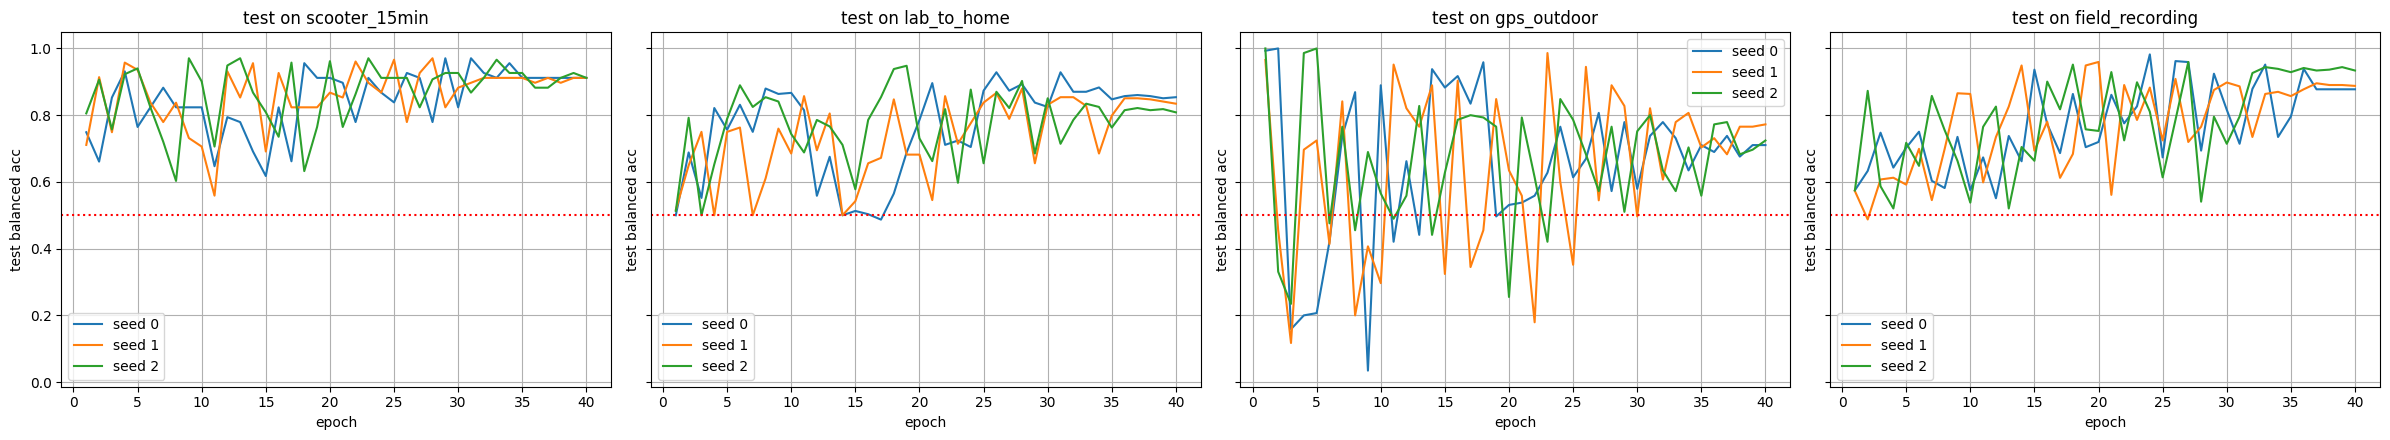

In [ ]:
# Leave-one-recording-out test.
# Each recording is used once as the test set while the model is trained on the other three, so the model is
# always tested on a recording it has never seen. Every split is trained with 3 seeds and the probabilities averaged.
# Saves the prediction of every test window (cnn_loro_predictions.csv) and a per-recording summary,
# and plots the test balanced accuracy per epoch for every split and seed.

def smooth_probs(meta, probs, n = 3):
    order = np.argsort(meta["t_start"].to_numpy())
    t = meta["t_start"].to_numpy()[order]
    segment = np.concatenate([[0], np.cumsum(np.diff(t) > step_s + 0.1)])
    p = pd.Series(probs[order, 1])
    p_smooth = p.groupby(segment).transform(lambda s: s.rolling(n, center = True, min_periods = 1).mean()).to_numpy()
    out = np.empty_like(p_smooth)
    out[order] = p_smooth
    return out

def recalls(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels = [0, 1])
    return cm.diagonal() / np.maximum(cm.sum(axis = 1), 1)

results = []
histories = {}
loro_parts = []
for test_rec in test_recs:
    test_idx = np.where(win_meta["recording"] == test_rec)[0]
    train_idx = np.where(win_meta["recording"] != test_rec)[0]
    y_test = y_all[test_idx]

    seed_probs, seed_acc = [], []
    for seed in seeds:
        model, hist, probs = train_model(train_idx, test_idx, seed = seed)
        seed_probs.append(probs)
        seed_acc.append(balanced_accuracy_score(y_test, probs.argmax(axis = 1)))
        histories[(test_rec, seed)] = hist
    ens = np.mean(seed_probs, axis = 0)
    p_asphalt_smooth = smooth_probs(win_meta.iloc[test_idx], ens)

    part = win_meta.iloc[test_idx][["recording", "t_start", "label"]].copy()
    part["p_asphalt"] = ens[:, 1]
    part["pred"] = np.where(ens[:, 1] >= 0.5, "asphalt", "sidewalk")
    loro_parts.append(part)

    pred_raw = ens.argmax(axis = 1)
    pred_smooth = (p_asphalt_smooth >= 0.5).astype(int)
    r_raw, r_smooth = recalls(y_test, pred_raw), recalls(y_test, pred_smooth)
    results.append({"test_on": test_rec, "n_sidewalk": int((y_test == 0).sum()), "n_asphalt": int((y_test == 1).sum()),
                    "seed_bal_acc_mean": np.mean(seed_acc), "seed_bal_acc_std": np.std(seed_acc),
                    "ens_recall_sidewalk": r_raw[0], "ens_recall_asphalt": r_raw[1],
                    "smooth_recall_sidewalk": r_smooth[0], "smooth_recall_asphalt": r_smooth[1],
                    "smooth_bal_acc": balanced_accuracy_score(y_test, pred_smooth)})
    print(f"done: test_on = {test_rec}")

loro = pd.concat(loro_parts, ignore_index = True)
loro["correct"] = loro["pred"] == loro["label"]
loro.to_csv(out_dir / "cnn_loro_predictions.csv", index = False)

results_df = pd.DataFrame(results)
display(results_df.round(3))
results_df.to_csv(out_dir / "cnn_loro_results_12s_accel.csv", index = False)

fig, axes = plt.subplots(1, len(test_recs), figsize = (24, 4.5), sharey = True)
for ax_plot, test_rec in zip(axes, test_recs):
    for seed in seeds:
        hist = histories[(test_rec, seed)]
        ax_plot.plot(hist["epoch"], hist["test_bal_acc"], label = f"seed {seed}")
    ax_plot.axhline(0.5, color = "r", linestyle = ":")
    ax_plot.set_title(f"test on {test_rec}")
    ax_plot.set_xlabel("epoch")
    ax_plot.set_ylabel("test balanced acc")
    ax_plot.grid(True)
    ax_plot.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Final model.
# Trained on all windows of all recordings (3 seeds) and saved with the normalization statistics and every
# preprocessing setting, so it can be applied to new recordings without a camera. The file is reloaded as a check.

final_idx = np.arange(len(win_meta))
final_states = []
for seed in seeds:
    model, hist, _ = train_model(final_idx, final_idx, seed = seed)
    final_states.append({k: v.cpu() for k, v in model.state_dict().items()})
    print(f"seed {seed}: final train loss = {hist['train_loss'].iloc[-1]:.3f}")

final_mean = X_sig[final_idx].mean(axis = (0, 2))[:, None]
final_std = X_sig[final_idx].std(axis = (0, 2))[:, None]

final_path = out_dir / "surface_cnn_final.pt"
torch.save({"state_dicts": final_states,
            "mean": final_mean, "std": final_std,
            "use_channels": use_channels, "classes": classes,
            "fs": fs, "win_s": win_s, "crop_len": crop_len,
            "band": (0.5, 80), "grav_hz": 0.3, "rms_min": float(np.e),
            "train_recordings": sorted(win_meta["recording"].unique()),
            "n_windows": int(len(final_idx))}, final_path)
print("saved:", final_path)

check = torch.load(final_path, weights_only = False)
reloaded = SurfaceCNN(n_in = len(check["use_channels"])).to(device)
reloaded.load_state_dict(check["state_dicts"][0])
print("reload ok:", sum(p.numel() for p in reloaded.parameters()), "parameters")

seed 0: final train loss = 0.042
seed 1: final train loss = 0.039
seed 2: final train loss = 0.036
saved: /content/drive/MyDrive/scooter_data/classification/surface_cnn_final.pt
reload ok: 130722 parameters


SURFACE CLASSIFICATION FROM IMU (leave-one-recording-out)
input: ['a_vert', 'a_horiz'], window = 12s, step = 2s, fs = 200 Hz
model: 1D-CNN, ensemble of 3 seeds, 40 epochs, cosine LR, augmentation
windows: 577  (sidewalk = 242, asphalt = 335)

per recording (model never saw the test recording):


,recording,n_sidewalk,n_asphalt,recall_sidewalk,recall_asphalt,accuracy
0,scooter_15min,34,115,0.824,1.000,0.960
1,lab_to_home,14,154,1.000,0.649,0.679
2,gps_outdoor,145,0,0.745,NaN,0.745
3,field_recording,49,66,0.816,1.000,0.922


pooled over all recordings:
  accuracy          = 0.816
  balanced accuracy = 0.812
  recall sidewalk   = 0.785
  recall asphalt    = 0.839

              precision    recall  f1-score   support

    sidewalk      0.779     0.785     0.782       242
     asphalt      0.844     0.839     0.841       335

    accuracy                          0.816       577
   macro avg      0.811     0.812     0.812       577
weighted avg      0.817     0.816     0.816       577

ablation (mean recall over recordings):


,setting,recall_sidewalk,recall_asphalt
0,4 s,0.715,0.857
1,8 s,0.791,0.875
2,12 s,0.846,0.883
3,12 s + gyro,0.824,0.802


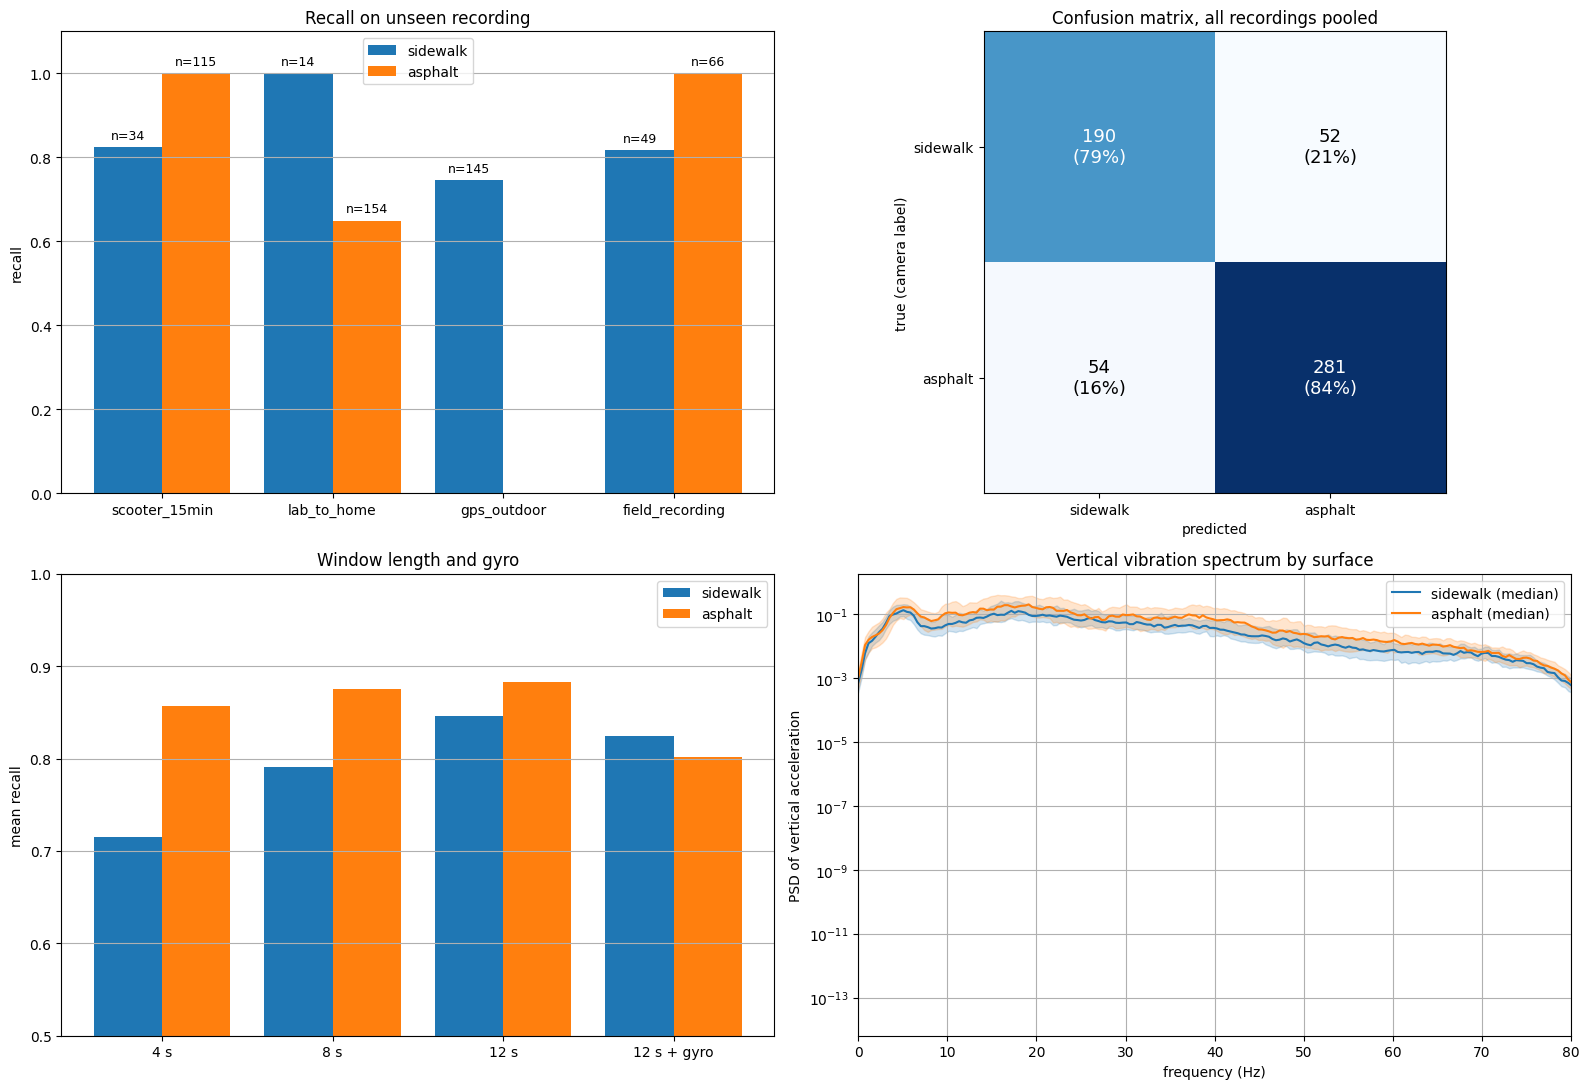

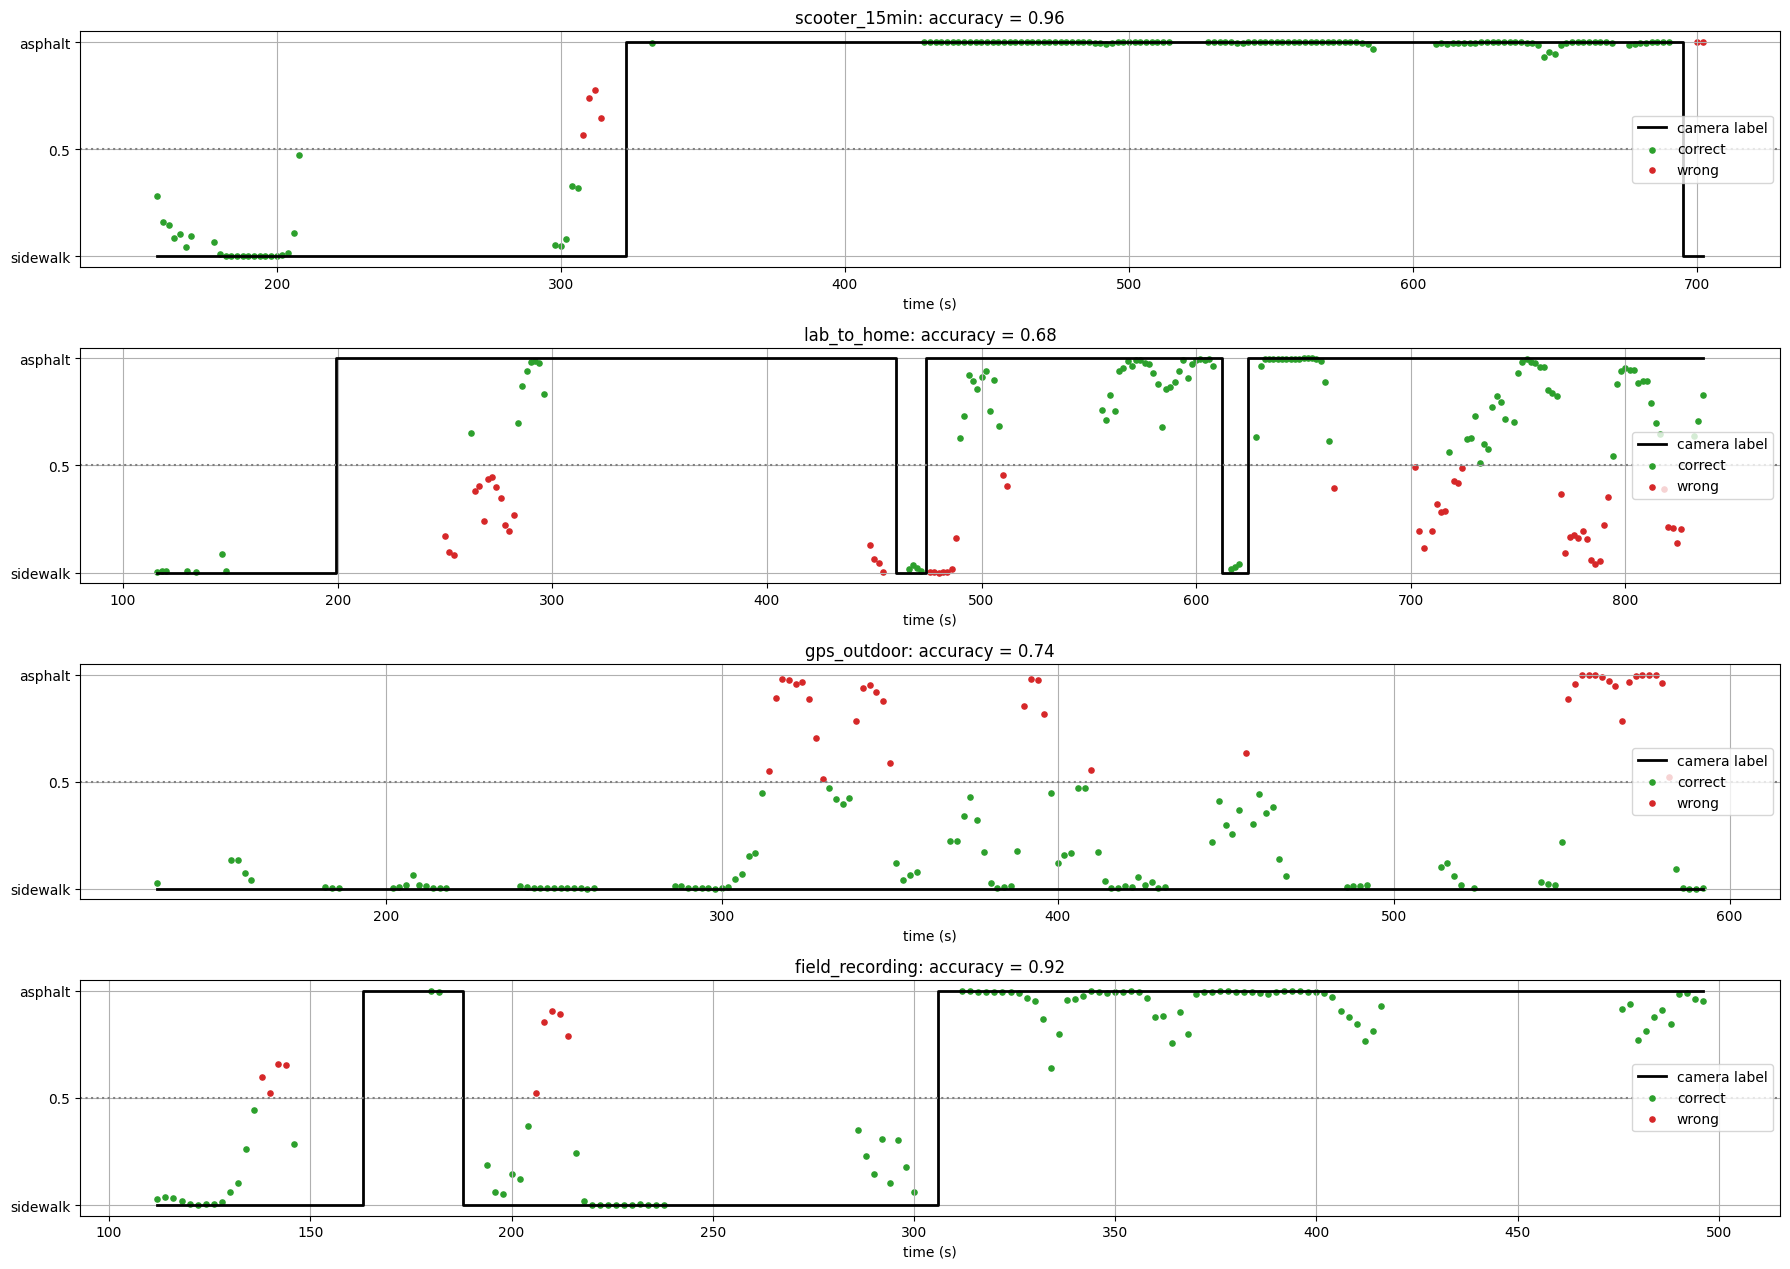

saved: /content/drive/MyDrive/scooter_data/classification/results_summary.png | /content/drive/MyDrive/scooter_data/classification/results_timelines.png


In [ ]:
# Results of the leave-one-recording-out test.
# Text: settings, recall and accuracy per recording, pooled metrics over all windows, classification report,
# and the ablation (mean recall from earlier runs with 4 / 8 / 12 s windows and with the gyro added).
# Figure 1: recall per recording (grouped bar chart), confusion matrix, ablation, and the vertical-vibration
# spectrum of each surface. Figure 2: prediction over time for each recording
# (black = camera label, dots = IMU p(asphalt), green = correct, red = wrong).

loro = pd.read_csv(out_dir / "cnn_loro_predictions.csv")

per_rec = []
for rec in test_recs:
    g = loro[loro["recording"] == rec]
    sw, asph = g[g["label"] == "sidewalk"], g[g["label"] == "asphalt"]
    per_rec.append({"recording": rec, "n_sidewalk": len(sw), "n_asphalt": len(asph),
                    "recall_sidewalk": (sw["pred"] == "sidewalk").mean() if len(sw) else np.nan,
                    "recall_asphalt": (asph["pred"] == "asphalt").mean() if len(asph) else np.nan,
                    "accuracy": g["correct"].mean()})
per_rec = pd.DataFrame(per_rec)

cm = confusion_matrix(loro["label"], loro["pred"], labels = classes)
pooled_recall = cm.diagonal() / cm.sum(axis = 1)

ablation = pd.DataFrame({"setting": ["4 s", "8 s", "12 s", "12 s + gyro"],
                         "recall_sidewalk": [0.715, 0.791, 0.846, 0.824],
                         "recall_asphalt": [0.857, 0.875, 0.883, 0.802]})

print("=" * 70)
print("SURFACE CLASSIFICATION FROM IMU (leave-one-recording-out)")
print("=" * 70)
print(f"input: {use_channels}, window = {win_s}s, step = {step_s}s, fs = {fs} Hz")
print(f"model: 1D-CNN, ensemble of {len(seeds)} seeds, 40 epochs, cosine LR, augmentation")
print(f"windows: {len(loro)}  (sidewalk = {(loro['label'] == 'sidewalk').sum()}, asphalt = {(loro['label'] == 'asphalt').sum()})")
print()
print("per recording (model never saw the test recording):")
display(per_rec.round(3))
print("pooled over all recordings:")
print(f"  accuracy          = {loro['correct'].mean():.3f}")
print(f"  balanced accuracy = {balanced_accuracy_score(loro['label'], loro['pred']):.3f}")
print(f"  recall sidewalk   = {pooled_recall[0]:.3f}")
print(f"  recall asphalt    = {pooled_recall[1]:.3f}")
print()
print(classification_report(loro["label"], loro["pred"], labels = classes, digits = 3))
print("ablation (mean recall over recordings):")
display(ablation)

fig, axes = plt.subplots(2, 2, figsize = (16, 11))

x = np.arange(len(test_recs))
axes[0, 0].bar(x - 0.2, per_rec["recall_sidewalk"].fillna(0), 0.4, label = "sidewalk")
axes[0, 0].bar(x + 0.2, per_rec["recall_asphalt"].fillna(0), 0.4, label = "asphalt")
for i, row in per_rec.iterrows():
    axes[0, 0].text(i - 0.2, row["recall_sidewalk"] + 0.02, f"n={row['n_sidewalk']}", ha = "center", fontsize = 9)
    if row["n_asphalt"] > 0:
        axes[0, 0].text(i + 0.2, row["recall_asphalt"] + 0.02, f"n={row['n_asphalt']}", ha = "center", fontsize = 9)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(test_recs)
axes[0, 0].set_ylim(0, 1.1)
axes[0, 0].set_ylabel("recall")
axes[0, 0].set_title("Recall on unseen recording")
axes[0, 0].legend()
axes[0, 0].grid(True, axis = "y")

axes[0, 1].imshow(cm, cmap = "Blues")
for i in range(2):
    for j in range(2):
        axes[0, 1].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha = "center", va = "center",
                        color = "white" if cm[i, j] > cm.max() / 2 else "black", fontsize = 13)
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_yticks([0, 1])
axes[0, 1].set_xticklabels(classes)
axes[0, 1].set_yticklabels(classes)
axes[0, 1].set_xlabel("predicted")
axes[0, 1].set_ylabel("true (camera label)")
axes[0, 1].set_title("Confusion matrix, all recordings pooled")

xa = np.arange(len(ablation))
axes[1, 0].bar(xa - 0.2, ablation["recall_sidewalk"], 0.4, label = "sidewalk")
axes[1, 0].bar(xa + 0.2, ablation["recall_asphalt"], 0.4, label = "asphalt")
axes[1, 0].set_xticks(xa)
axes[1, 0].set_xticklabels(ablation["setting"])
axes[1, 0].set_ylim(0.5, 1)
axes[1, 0].set_ylabel("mean recall")
axes[1, 0].set_title("Window length and gyro")
axes[1, 0].legend()
axes[1, 0].grid(True, axis = "y")

for c, color in [("sidewalk", "tab:blue"), ("asphalt", "tab:orange")]:
    sig = X_sig[win_meta["label"].to_numpy() == c, 0, :]
    f, p = welch(sig, fs = fs, nperseg = 512, axis = 1)
    axes[1, 1].semilogy(f, np.median(p, axis = 0), color = color, label = f"{c} (median)")
    axes[1, 1].fill_between(f, np.percentile(p, 25, axis = 0), np.percentile(p, 75, axis = 0), color = color, alpha = 0.2)
axes[1, 1].set_xlim(0, 80)
axes[1, 1].set_xlabel("frequency (Hz)")
axes[1, 1].set_ylabel("PSD of vertical acceleration")
axes[1, 1].set_title("Vertical vibration spectrum by surface")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(out_dir / "results_summary.png", dpi = 150)
plt.show()

fig, axes = plt.subplots(len(test_recs), 1, figsize = (18, 3.2 * len(test_recs)))
for ax_plot, rec in zip(axes, test_recs):
    g = loro[loro["recording"] == rec].sort_values("t_start")
    t_mid = g["t_start"] + win_s / 2
    truth = (g["label"] == "asphalt").astype(int)
    ax_plot.step(t_mid, truth, where = "mid", color = "k", linewidth = 2, label = "camera label")
    ax_plot.scatter(t_mid[g["correct"]], g.loc[g["correct"], "p_asphalt"], s = 14, color = "tab:green", label = "correct")
    ax_plot.scatter(t_mid[~g["correct"]], g.loc[~g["correct"], "p_asphalt"], s = 14, color = "tab:red", label = "wrong")
    ax_plot.axhline(0.5, color = "gray", linestyle = ":")
    ax_plot.set_yticks([0, 0.5, 1])
    ax_plot.set_yticklabels(["sidewalk", "0.5", "asphalt"])
    ax_plot.set_title(f"{rec}: accuracy = {g['correct'].mean():.2f}")
    ax_plot.set_xlabel("time (s)")
    ax_plot.grid(True)
    ax_plot.legend(loc = "center right")
plt.tight_layout()
plt.savefig(out_dir / "results_timelines.png", dpi = 150)
plt.show()

print("saved:", out_dir / "results_summary.png", "|", out_dir / "results_timelines.png")

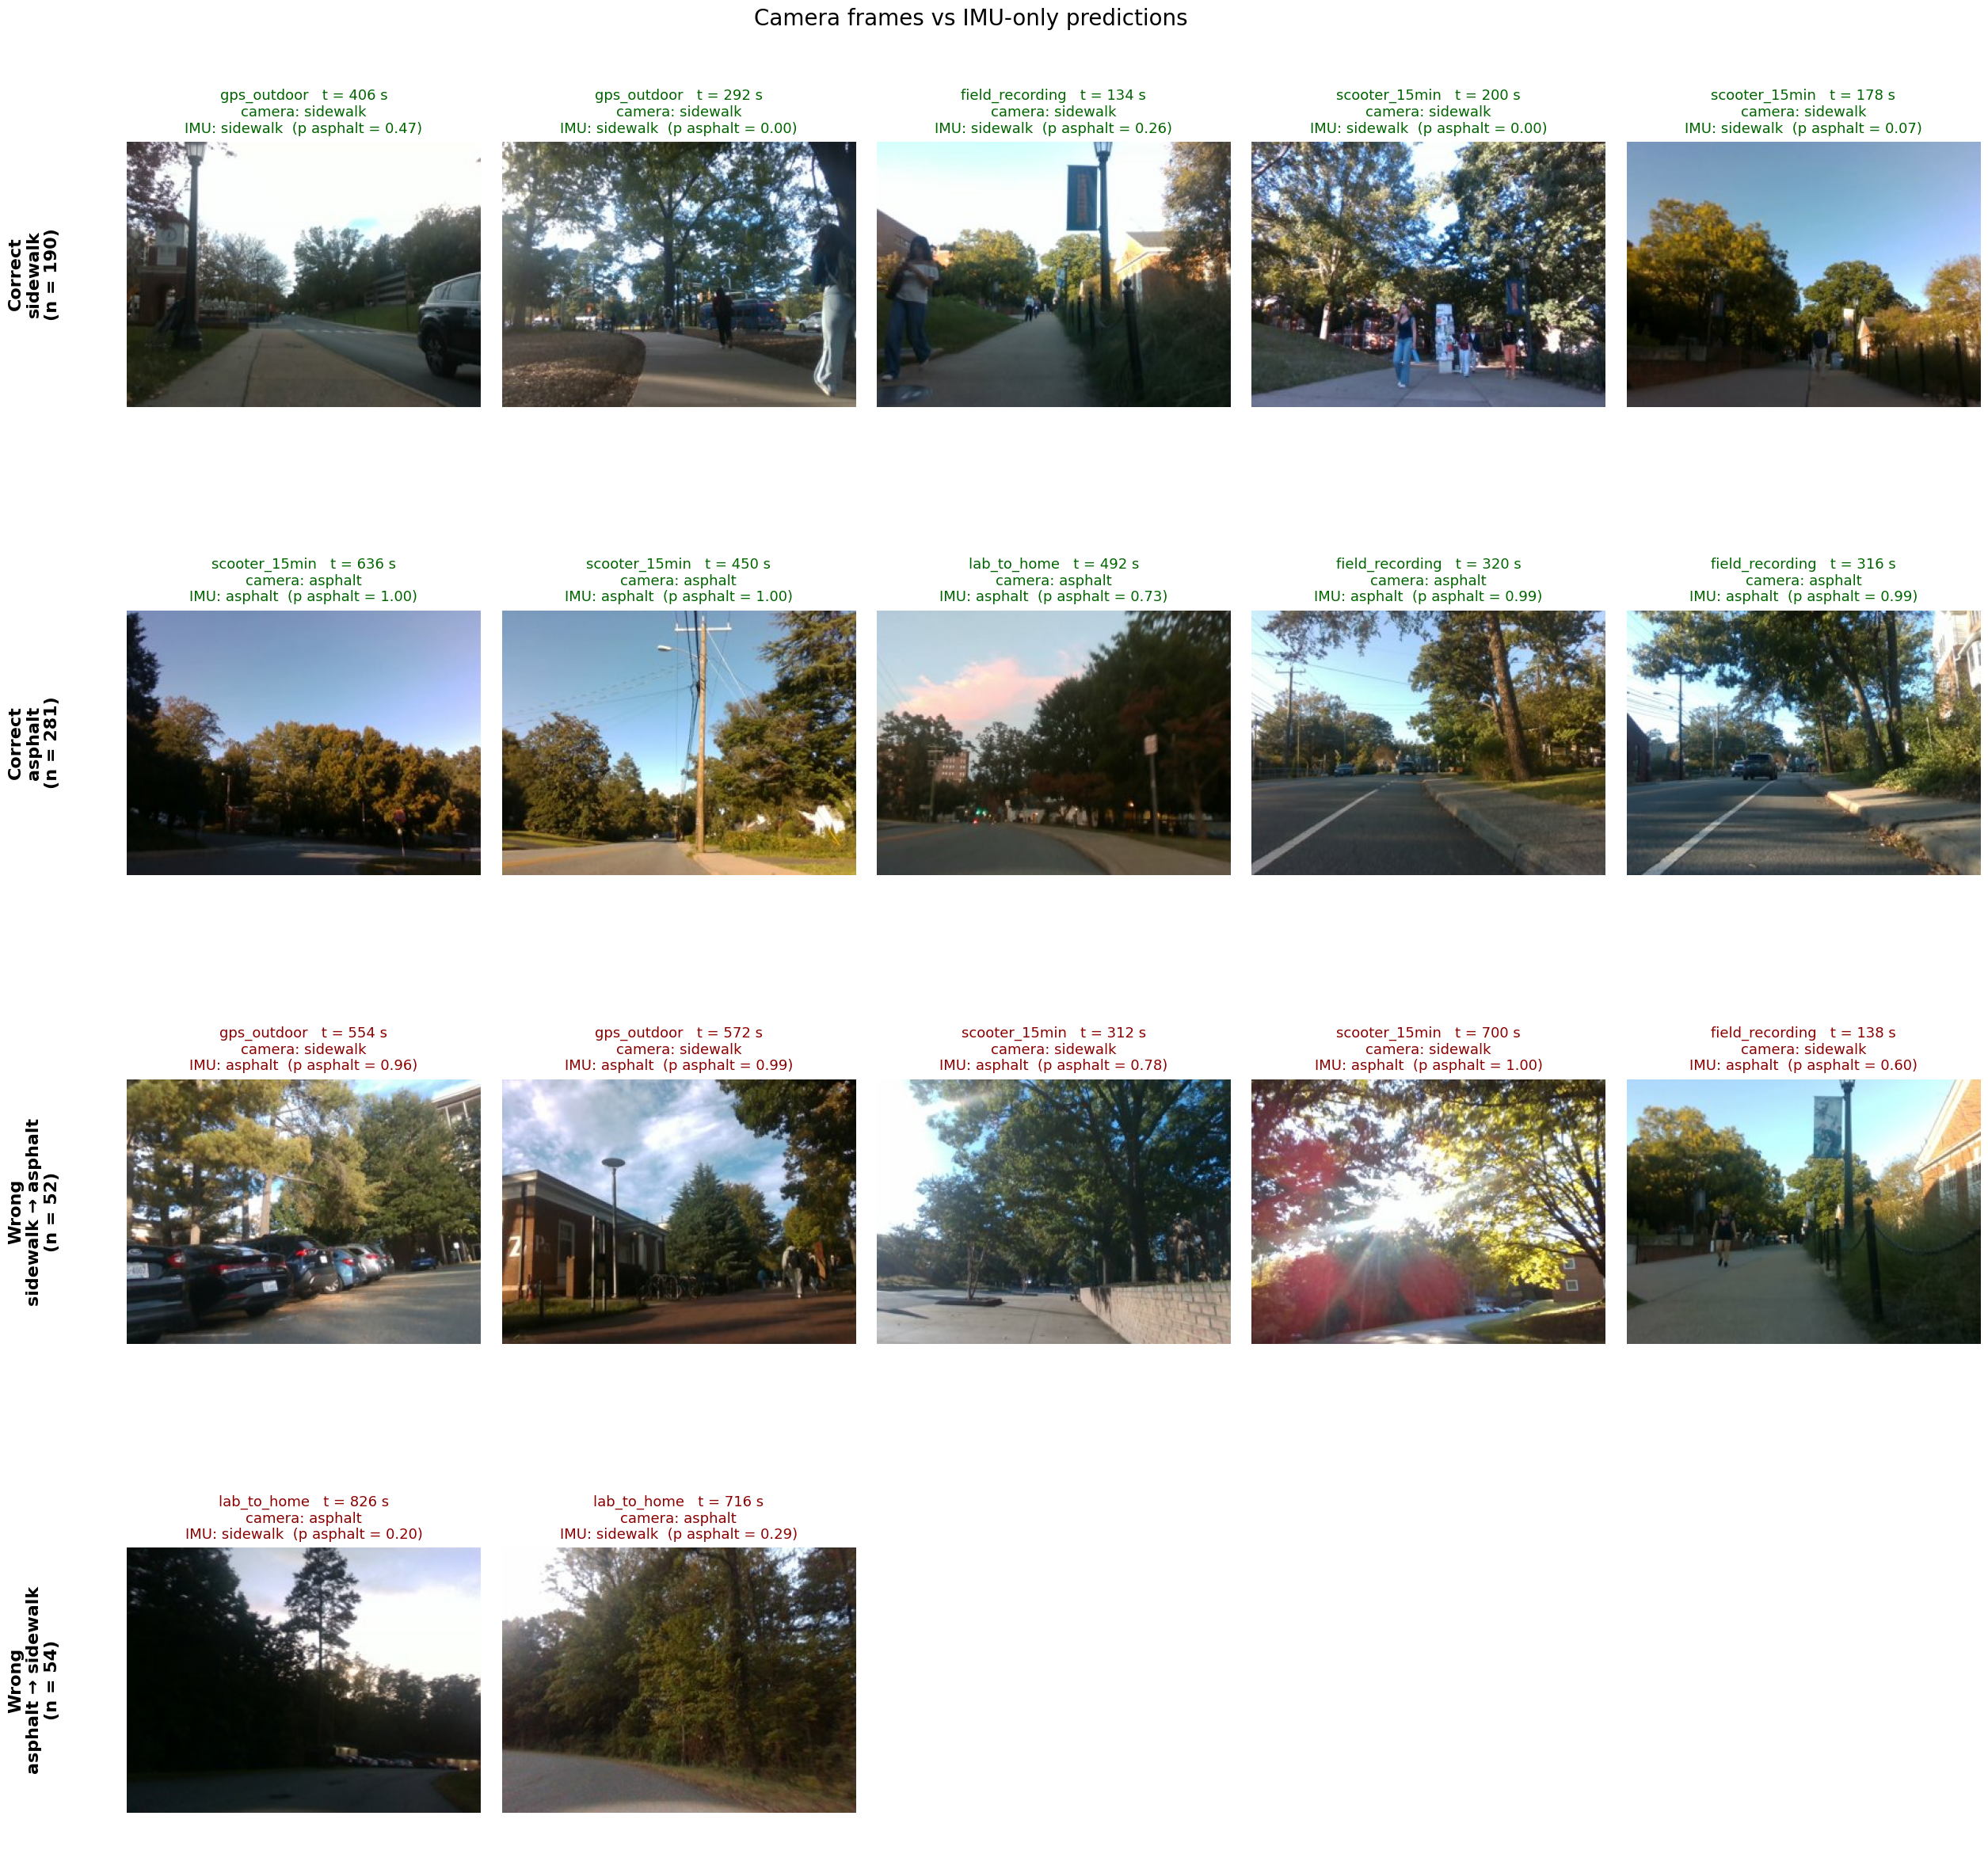

saved: /content/drive/MyDrive/scooter_data/classification/results_frames_grid.png


In [ ]:
# Camera frames vs IMU predictions.
# For every test window, the camera frame closest to its middle is shown next to the IMU prediction,
# in four rows: correct sidewalk, correct asphalt, and the two kinds of errors.
# Frames are only used for this visual check, never as model input.

frames_root = out_dir / "frames_all"
frame_index = pd.concat([pd.read_csv(frames_root / f"{r}_frames.csv") for r in test_recs], ignore_index = True)

def nearest_frame(rec, t):
    f = frame_index[frame_index["recording"] == rec]
    i = (f["t"] - t).abs().idxmin()
    return f.loc[i, "frame"], abs(f.loc[i, "t"] - t)

loro["t_mid"] = loro["t_start"] + win_s / 2
nearest = [nearest_frame(r, t) for r, t in zip(loro["recording"], loro["t_mid"])]
loro["frame"] = [p for p, _ in nearest]
loro["frame_dt"] = [d for _, d in nearest]
shown = loro[loro["frame_dt"] < 1.5]

groups = [("sidewalk", "sidewalk", "Correct\nsidewalk"),
          ("asphalt", "asphalt", "Correct\nasphalt"),
          ("sidewalk", "asphalt", "Wrong\nsidewalk → asphalt"),
          ("asphalt", "sidewalk", "Wrong\nasphalt → sidewalk")]
n_cols = 5

fig, axes = plt.subplots(len(groups), n_cols, figsize = (26, 6 * len(groups)))
fig.subplots_adjust(left = 0.09, right = 0.99, top = 0.93, bottom = 0.02, hspace = 0.45, wspace = 0.06)

for row, (true_c, pred_c, title) in enumerate(groups):
    g = shown[(shown["label"] == true_c) & (shown["pred"] == pred_c)]
    sample = g.sample(frac = 1, random_state = 0).groupby("recording").head(2).head(n_cols)
    for col in range(n_cols):
        ax_plot = axes[row, col]
        ax_plot.axis("off")
        if col < len(sample):
            r = sample.iloc[col]
            ax_plot.imshow(Image.open(r["frame"]))
            color = "darkgreen" if r["label"] == r["pred"] else "darkred"
            ax_plot.set_title(f"{r['recording']}   t = {r['t_mid']:.0f} s\n"
                              f"camera: {r['label']}\n"
                              f"IMU: {r['pred']}  (p asphalt = {r['p_asphalt']:.2f})",
                              fontsize = 13, color = color, pad = 8)
    pos = axes[row, 0].get_position()
    fig.text(0.045, (pos.y0 + pos.y1) / 2, f"{title}\n(n = {len(g)})", rotation = 90,
             ha = "center", va = "center", fontsize = 16, fontweight = "bold")

fig.suptitle("Camera frames vs IMU-only predictions", fontsize = 20, y = 0.985)
plt.savefig(out_dir / "results_frames_grid.png", dpi = 120, bbox_inches = "tight")
plt.show()
print("saved:", out_dir / "results_frames_grid.png")

In [ ]:
# Check against the hand-labelled frames only.
# For every hand-labelled frame, the IMU predictions of the test windows that contain it are averaged and
# compared with the hand label. This removes the error of the automatic camera labels from the evaluation.

manual = pd.read_csv(out_dir / "manual_labels.csv")
manual = manual[manual["manual"].isin(classes)]

rows = []
for _, m in manual.iterrows():
    w = loro[(loro["recording"] == m["recording"]) & (loro["t_start"] <= m["t"]) & (loro["t_start"] + win_s > m["t"])]
    if len(w) == 0:
        continue
    p = w["p_asphalt"].mean()
    rows.append({"recording": m["recording"], "t": m["t"], "human": m["manual"],
                 "p_asphalt": p, "imu": "asphalt" if p >= 0.5 else "sidewalk"})
gold = pd.DataFrame(rows)
gold["correct"] = gold["human"] == gold["imu"]

print(f"hand-labeled frames: {len(manual)},  inside a riding window: {len(gold)}")
print()
cm_gold = confusion_matrix(gold["human"], gold["imu"], labels = classes)
print("IMU prediction vs YOUR labels (rows = your label, cols = IMU) [sidewalk, asphalt]:")
print(cm_gold)
print()
print(f"accuracy          = {gold['correct'].mean():.3f}")
print(f"balanced accuracy = {balanced_accuracy_score(gold['human'], gold['imu']):.3f}")
print(f"recall sidewalk   = {cm_gold[0, 0] / cm_gold[0].sum():.3f}  (n = {cm_gold[0].sum()})")
print(f"recall asphalt    = {cm_gold[1, 1] / cm_gold[1].sum():.3f}  (n = {cm_gold[1].sum()})")
print()
print(gold.groupby("recording")["correct"].agg(["count", "mean"]).round(3))
gold.to_csv(out_dir / "imu_vs_manual_labels.csv", index = False)

hand-labeled frames: 150,  inside a riding window: 122

IMU prediction vs YOUR labels (rows = your label, cols = IMU) [sidewalk, asphalt]:
[[54 10]
 [ 4 54]]

accuracy          = 0.885
balanced accuracy = 0.887
recall sidewalk   = 0.844  (n = 64)
recall asphalt    = 0.931  (n = 58)

                 count   mean
recording                    
field_recording     33  0.909
gps_outdoor         34  0.882
lab_to_home         28  0.857
scooter_15min       27  0.889
